# VGGMM experiments — shape2 initialization
모델은 vggmm_merge_refit.py, 공통 평가·표·그림은 vggmm_experiments.py에서 불러옵니다.
두 .py와 이 노트북을 같은 폴더에 두고, VS Code에서 그 폴더를 열어 실행하세요.

모든 GGMM 최초 성분과 병합 성분은 b=2에서 출발합니다. 이후 b는 자유롭게 추정합니다.
생성에 사용하는 참 GGD의 형상 (1.5, 4, 8 등)은 바꾸지 않습니다.
기존 moment 출력은 옮기지 않았습니다. 아래 출력은 새 설정으로 다시 계산됩니다.
전체 실행은 여러 번의 실제 적합을 수행합니다. 한 실험만 필요하면 준비 셀 뒤 해당 셀을 실행하세요.

검증 출력은 준비 셀과 N=5,000의 단일 cap=10 실행입니다. 나머지 원래 크기의 실험은 미실행 상태입니다.


In [1]:
from pathlib import Path
import importlib
import numpy as np
import pandas as pd
import vggmm_merge_refit as vg
import vggmm_experiments as ex

importlib.reload(vg)
importlib.reload(ex)

N = 5000
SEED = 20260912
SEEDS = (20260912, 20260913, 20260914)
CAPS = (10, 11, 12, 13, 14, 15)
BASE_CONFIG = vg.VGGMMConfig(initial_shape_mode="shape2", enable_merge=True)
OUTPUT_ROOT = Path("results")
FIGURE_FORMATS = ("png", "svg", "pdf")
ex.check_mathematics()
print("Model:", Path(vg.__file__).name, "| initialization:", BASE_CONFIG.initial_shape_mode)

Math checks passed: normal moment, Gamma profile/ELBO, sticks.
Model: vggmm_merge_refit.py | initialization: shape2


## 표본 준비
기존 세 GGD 생성식과 표본 추출 순서를 유지합니다. 추정기에 주는 입력은 X뿐입니다.


In [2]:
truth3 = ex.ggd_reference_3()
X = ex.sample_mixture(truth3, N, SEED)
X.setflags(write=False)
print(f"N={len(X):,}; seed={SEED}; true K={truth3.k}")

N=5,000; seed=20260912; true K=3


## 1. 최대 성분 수 10
두 초기화와 merge 탐색을 포함하는 fit(X) 한 번입니다. 시간·오차·수렴·밀도·성분 그래프를 표시합니다.
Fit_s(merge)는 baseline을 포함합니다. baseline과 merge 시간을 다시 합산하지 않습니다.



max_K=10: baseline + merge (shape2)
    merge (8, 9): K 10->9, ELBO/n +0.00384123
    merge (7, 8): K 9->8, ELBO/n +0.00360515
    merge (6, 7): K 8->7, ELBO/n +0.00381053
    merge (5, 6): K 7->6, ELBO/n +0.00392841
    merge (0, 1): K 6->5, ELBO/n +0.000559909
    merge (3, 4): K 5->4, ELBO/n +0.00051329
    merge (2, 3): K 4->3, ELBO/n +0.000517954
  VGGMM-base: Active_K=10, ELBO/n=-2.4724743, IAE=0.0593076, merges=0
  VGGMM-merge: Active_K=3, ELBO/n=-2.4556025, IAE=0.0292802, merges=7


,Method,Max_K,Active_K,Excluded_mass,IAE,ISE,Converged,Inner_nonconverged,Accepted_merges,Fit_s,Evaluation_s,Quadrature_OK
0,VGGMM-base,10,10,0.000000,0.059308,0.000496,True,0,0,135.292221,0.165391,True
1,VGGMM-merge,10,3,0.000600,0.029280,0.000093,True,0,7,169.942226,0.072862,True
2,VGM,10,5,0.001275,0.108209,0.001250,True,0,0,0.731210,0.114334,True


,Max_K,Base_active_K,Merge_active_K,Base_IAE,Merge_IAE,Base_ISE,Merge_ISE,Total_delta_ELBO_per_observation,Accepted_merge_ELBO_gain_per_observation,Continuation_ELBO_gain_per_observation,Accepted_merges,Merge_stop_reason,BaseFit_s,MergeExtra_s,TotalFit_s
0,10,10,3,0.059308,0.02928,0.000496,0.000093,0.016872,0.016776,0.000095,7,no_improvement_in_all_prepared_adjacent_pairs,135.292221,34.649595,169.942226


,Method,Max_K,Baseline_fit_s,Merge_extra_s,Finalization_s,Total_fit_s,Continuation_s,Pair_pool_s,Seed_screening_s,Candidate_refit_s,Merge_management_s,Initial_starts_attempted,Continuation_refits,Candidate_seeds,Candidate_refits,Accepted_merges,Evaluation_s
0,VGGMM-base+merge,10,135.292221,34.649595,0.00041,169.942226,7.505659,0.002304,5.390809,21.74404,0.006782,2.0,8.0,44.0,10.0,7.0,0.238253
1,VGM,10,0.731210,0.000000,0.00000,0.731210,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.114334


Fit_s(merge) includes baseline; Evaluation_s is separate.
Density errors here use the active, renormalized density; *_full uses all slots.
Results: results\single_cap_10\20261016T085821_105417Z


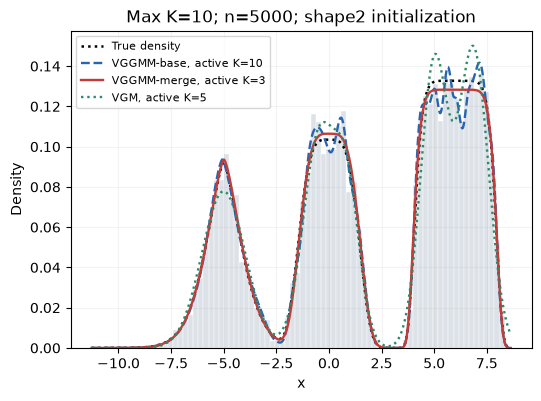

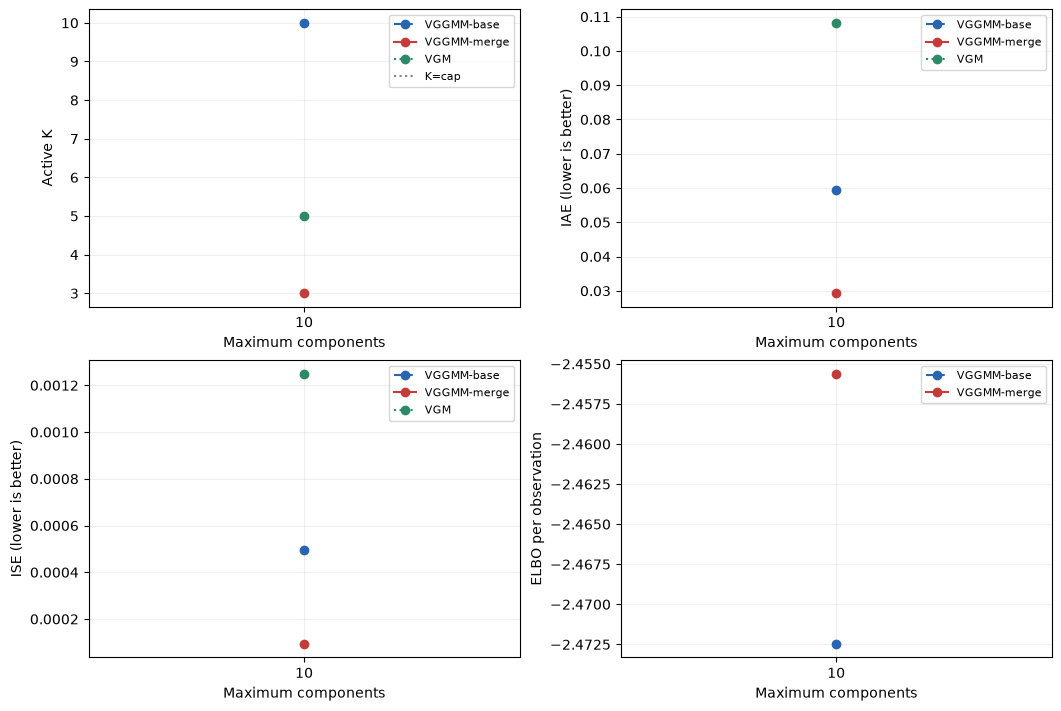

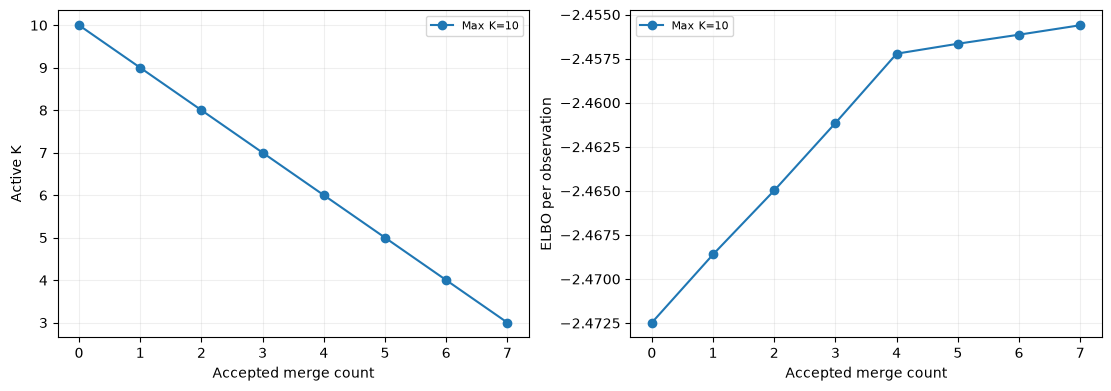

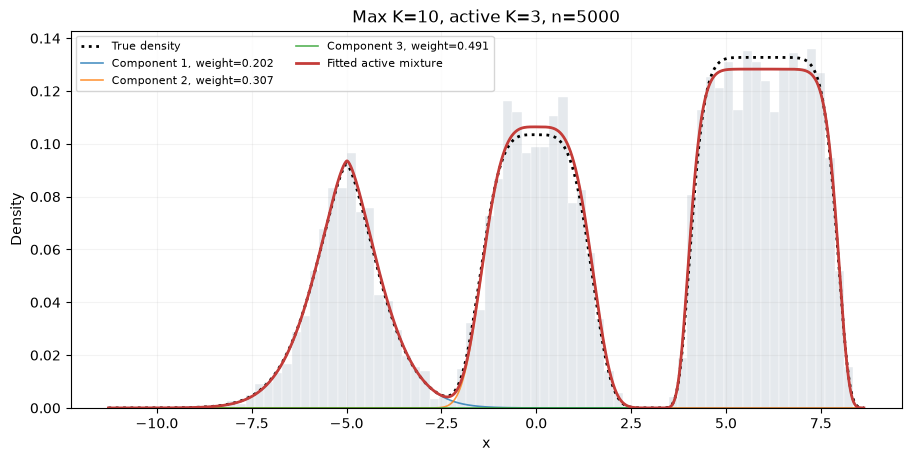

In [3]:
single_cap = ex.run_cap_experiment(
    X, truth3, caps=(10,), config=BASE_CONFIG,
    name="single_cap_10", output_root=OUTPUT_ROOT, include_vgm=True)
model10 = single_cap["models"][10]
ex.show_cap_results(single_cap)
ex.plot_cap_results(single_cap, formats=FIGURE_FORMATS, components=True)

## 2. 최대 성분 수 10~15 비교
각 상한에서 독립적으로 새 적합을 합니다. 단일 실험과 별도로 소요 시간을 측정합니다.
첫 셀의 CAPS를 (10,)로 지정하면 이 실험도 10 하나만 실행할 수 있습니다.



max_K=10: baseline + merge (shape2)
    merge (8, 9): K 10->9, ELBO/n +0.00384123
    merge (7, 8): K 9->8, ELBO/n +0.00360515
    merge (6, 7): K 8->7, ELBO/n +0.00381053
    merge (5, 6): K 7->6, ELBO/n +0.00392841
    merge (0, 1): K 6->5, ELBO/n +0.000559909
    merge (3, 4): K 5->4, ELBO/n +0.00051329
    merge (2, 3): K 4->3, ELBO/n +0.000517954
  VGGMM-base: Active_K=10, ELBO/n=-2.4724743, IAE=0.0593076, merges=0
  VGGMM-merge: Active_K=3, ELBO/n=-2.4556025, IAE=0.0292802, merges=7

max_K=11: baseline + merge (shape2)
    merge (9, 10): K 10->9, ELBO/n +0.00363168
    merge (8, 9): K 9->8, ELBO/n +0.00387039
    merge (7, 8): K 8->7, ELBO/n +0.00373866
    merge (6, 7): K 7->6, ELBO/n +0.00391478
    merge (3, 4): K 6->5, ELBO/n +0.00125282
    merge (0, 1): K 5->4, ELBO/n +0.000587967
    merge (2, 3): K 4->3, ELBO/n +0.000504342
  VGGMM-base: Active_K=10, ELBO/n=-2.4761414, IAE=0.0584931, merges=0
  VGGMM-merge: Active_K=3, ELBO/n=-2.4585454, IAE=0.0294127, merges=7

max_K=12

,Method,Max_K,Active_K,Excluded_mass,IAE,ISE,Converged,Inner_nonconverged,Accepted_merges,Fit_s,Evaluation_s,Quadrature_OK
0,VGGMM-base,10,10,0.000000,0.059308,0.000496,True,0,0,136.212120,0.160416,True
1,VGGMM-merge,10,3,0.000600,0.029280,0.000093,True,0,7,170.385709,0.071542,True
2,VGM,10,5,0.001275,0.108209,0.001250,True,0,0,0.691493,0.122581,True
3,VGGMM-base,11,10,0.000200,0.058493,0.000486,True,0,0,115.310570,0.170773,True
4,VGGMM-merge,11,3,0.000799,0.029413,0.000094,True,0,7,144.480767,0.069154,True
5,VGM,11,5,0.001276,0.108168,0.001250,True,0,0,0.744374,0.126467,True
6,VGGMM-base,12,11,0.003360,0.060900,0.000516,True,0,0,147.828072,0.190944,True
7,VGGMM-merge,12,3,0.000799,0.029309,0.000093,True,0,9,198.771977,0.072117,True
8,VGM,12,5,0.001779,0.109730,0.001270,True,0,0,0.946068,0.156216,True
9,VGGMM-base,13,11,0.002618,0.061054,0.000541,True,0,0,151.573598,0.204270,True


,Max_K,Base_active_K,Merge_active_K,Base_IAE,Merge_IAE,Base_ISE,Merge_ISE,Total_delta_ELBO_per_observation,Accepted_merge_ELBO_gain_per_observation,Continuation_ELBO_gain_per_observation,Accepted_merges,Merge_stop_reason,BaseFit_s,MergeExtra_s,TotalFit_s
0,10,10,3,0.059308,0.029280,0.000496,0.000093,0.016872,0.016776,0.000095,7,no_improvement_in_all_prepared_adjacent_pairs,136.212120,34.173347,170.385709
1,11,10,3,0.058493,0.029413,0.000486,0.000094,0.017596,0.017501,0.000095,7,no_improvement_in_all_prepared_adjacent_pairs,115.310570,29.169952,144.480767
2,12,11,3,0.060900,0.029309,0.000516,0.000093,0.022400,0.022295,0.000105,9,no_improvement_in_all_prepared_adjacent_pairs,147.828072,50.943687,198.771977
3,13,11,3,0.061054,0.029444,0.000541,0.000094,0.021010,0.020897,0.000113,9,no_improvement_in_all_prepared_adjacent_pairs,151.573598,49.086401,200.660322
4,14,14,3,0.070550,0.029444,0.000645,0.000094,0.026924,0.026739,0.000185,11,no_improvement_in_all_prepared_adjacent_pairs,100.600753,81.416165,182.017233
5,15,14,3,0.073977,0.029571,0.000702,0.000095,0.027055,0.026643,0.000412,11,no_improvement_in_all_prepared_adjacent_pairs,130.711804,88.813207,219.525310


,Method,Max_K,Baseline_fit_s,Merge_extra_s,Finalization_s,Total_fit_s,Continuation_s,Pair_pool_s,Seed_screening_s,Candidate_refit_s,Merge_management_s,Initial_starts_attempted,Continuation_refits,Candidate_seeds,Candidate_refits,Accepted_merges,Evaluation_s
0,VGGMM-base+merge,10,136.212120,34.173347,0.000242,170.385709,7.512092,0.002344,5.372485,21.280190,0.006235,2.0,8.0,44.0,10.0,7.0,0.231958
1,VGM,10,0.691493,0.000000,0.000000,0.691493,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.122581
2,VGGMM-base+merge,11,115.310570,29.169952,0.000246,144.480767,7.920284,0.002243,7.086183,14.153909,0.007332,2.0,8.0,44.0,9.0,7.0,0.239927
3,VGM,11,0.744374,0.000000,0.000000,0.744374,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.126467
4,VGGMM-base+merge,12,147.828072,50.943687,0.000219,198.771977,13.514209,0.003119,8.502818,28.913638,0.009903,2.0,10.0,65.0,11.0,9.0,0.263061
5,VGM,12,0.946068,0.000000,0.000000,0.946068,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.156216
6,VGGMM-base+merge,13,151.573598,49.086401,0.000323,200.660322,12.161920,0.003142,7.454550,29.457260,0.009528,2.0,10.0,65.0,12.0,9.0,0.286172
7,VGM,13,0.724593,0.000000,0.000000,0.724593,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.140931
8,VGGMM-base+merge,14,100.600753,81.416165,0.000315,182.017233,15.828958,0.004226,10.226735,55.343107,0.013140,2.0,12.0,90.0,13.0,11.0,0.358619
9,VGM,14,0.765958,0.000000,0.000000,0.765958,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.139565


Fit_s(merge) includes baseline; Evaluation_s is separate.
Density errors here use the active, renormalized density; *_full uses all slots.
Results: results\cap_sweep\20261016T090117_402806Z


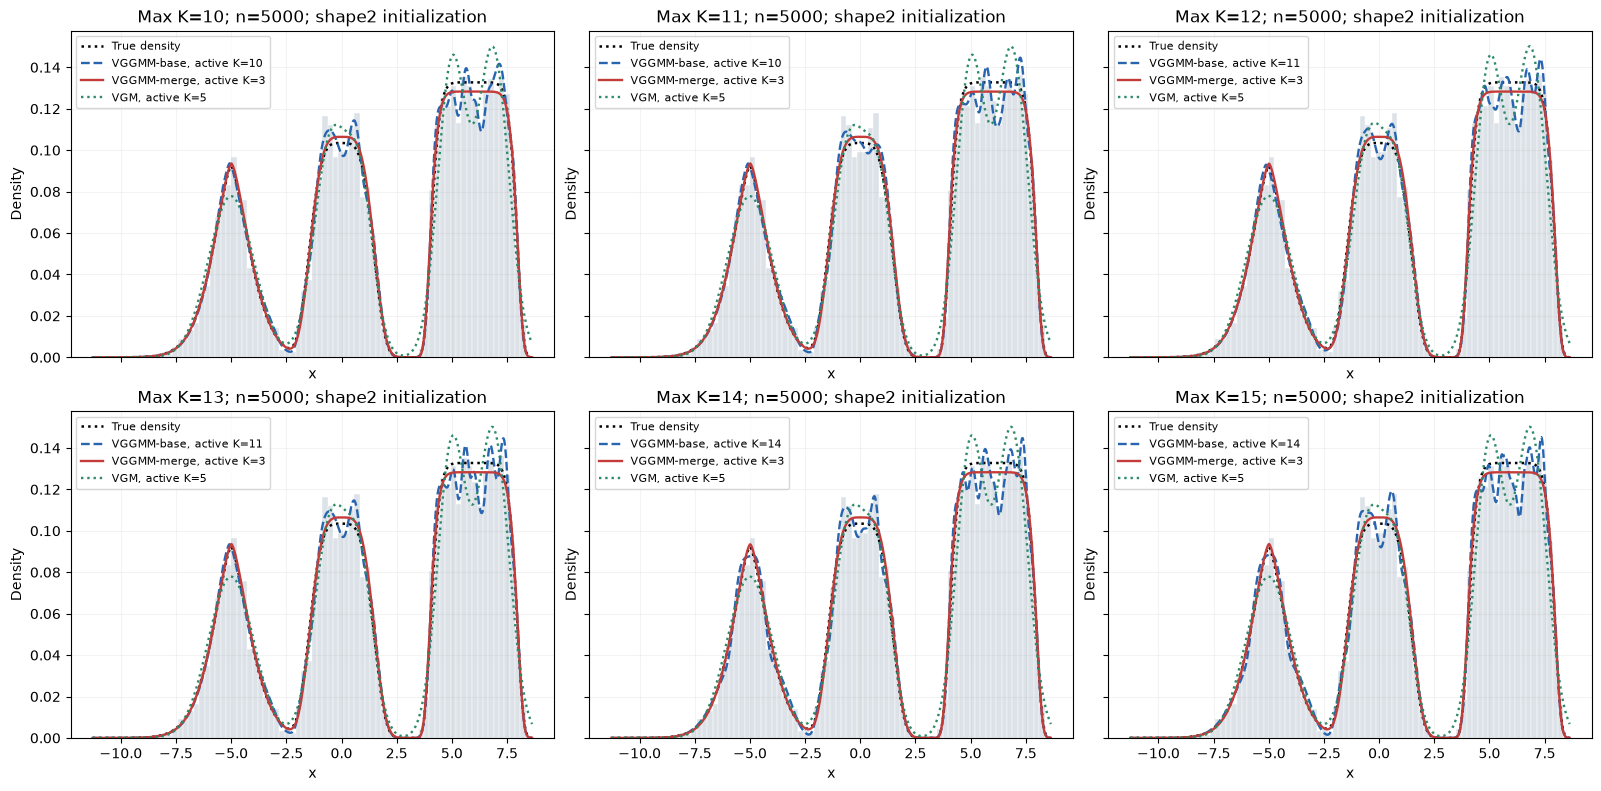

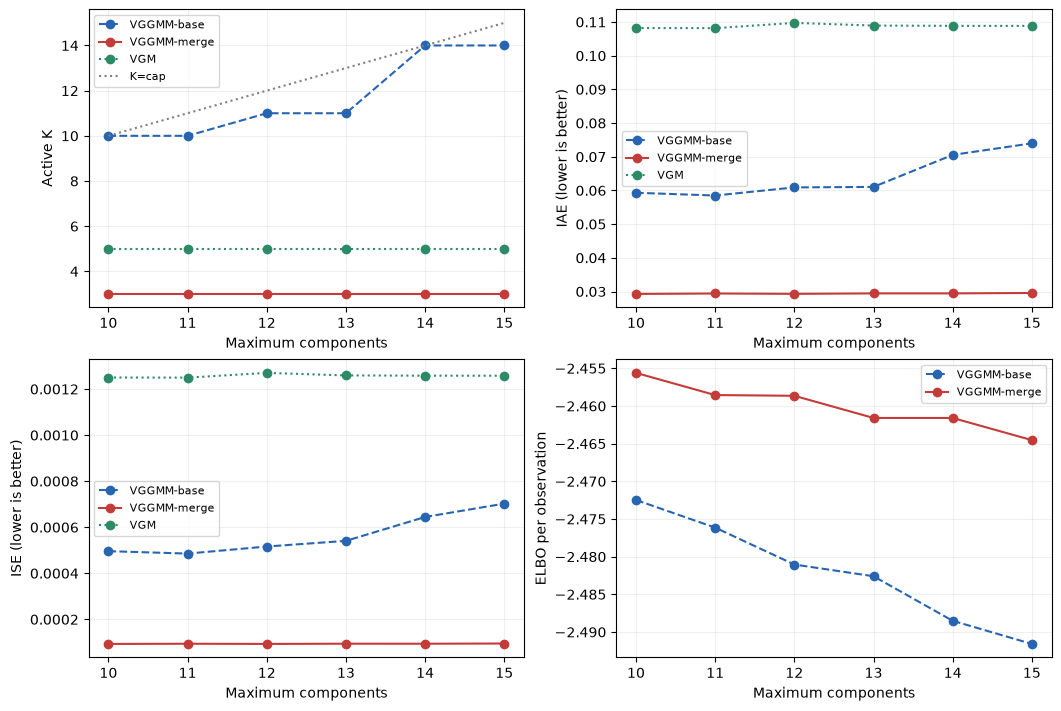

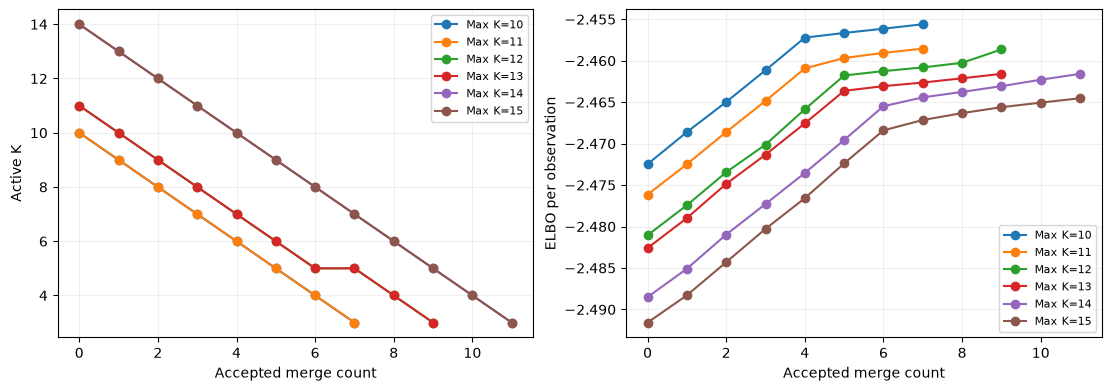

In [4]:
cap_sweep = ex.run_cap_experiment(
    X, truth3, caps=CAPS, config=BASE_CONFIG,
    name="cap_sweep", output_root=OUTPUT_ROOT, include_vgm=True)
ex.show_cap_results(cap_sweep)
ex.plot_cap_results(cap_sweep, formats=FIGURE_FORMATS)

## 3. 참 성분 수 5에서 최대 성분 수 3과 10
기존 생성식·표본 수·seed를 유지하며 VGM 없이 병합 전후를 비교합니다.



max_K=3: baseline + merge (shape2)
  VGGMM-base: Active_K=3, ELBO/n=-3.0758480, IAE=0.3244036, merges=0
  VGGMM-merge: Active_K=3, ELBO/n=-3.0758453, IAE=0.3244368, merges=0

max_K=10: baseline + merge (shape2)
    merge (8, 9): K 9->8, ELBO/n +0.00358856
    merge (7, 8): K 8->7, ELBO/n +0.00329105
    merge (5, 6): K 7->6, ELBO/n +0.00135773
    merge (1, 2): K 6->5, ELBO/n +0.00045962
    merge (3, 4): K 5->5, ELBO/n +0.000394588
  VGGMM-base: Active_K=10, ELBO/n=-2.9760580, IAE=0.0491440, merges=0
  VGGMM-merge: Active_K=5, ELBO/n=-2.9668932, IAE=0.0437463, merges=5


,Method,Max_K,Active_K,Excluded_mass,IAE,ISE,Converged,Inner_nonconverged,Accepted_merges,Fit_s,Evaluation_s,Quadrature_OK
0,VGGMM-base,3,3,0.000000,0.324404,0.007856,True,0,0,16.526824,0.097349,True
1,VGGMM-merge,3,3,0.000000,0.324437,0.007855,True,0,0,19.094731,0.088035,True
2,VGGMM-base,10,10,0.000000,0.049144,0.000174,True,0,0,55.956456,0.177994,True
3,VGGMM-merge,10,5,0.000599,0.043746,0.000131,True,0,5,82.196698,0.126746,True


,Max_K,Base_active_K,Merge_active_K,Base_IAE,Merge_IAE,Base_ISE,Merge_ISE,Total_delta_ELBO_per_observation,Accepted_merge_ELBO_gain_per_observation,Continuation_ELBO_gain_per_observation,Accepted_merges,Merge_stop_reason,BaseFit_s,MergeExtra_s,TotalFit_s
0,3,3,3,0.324404,0.324437,0.007856,0.007855,0.000003,0.000000,0.000003,0,no_improvement_in_all_prepared_adjacent_pairs,16.526824,2.567691,19.094731
1,10,10,5,0.049144,0.043746,0.000174,0.000131,0.009165,0.009092,0.000073,5,candidate_budget_exhausted_without_improvement,55.956456,26.239956,82.196698


,Method,Max_K,Baseline_fit_s,Merge_extra_s,Finalization_s,Total_fit_s,Continuation_s,Pair_pool_s,Seed_screening_s,Candidate_refit_s,Merge_management_s,Initial_starts_attempted,Continuation_refits,Candidate_seeds,Candidate_refits,Accepted_merges,Evaluation_s
0,VGGMM-base+merge,3,16.526824,2.567691,0.000216,19.094731,0.273001,0.000129,0.318112,1.976171,0.000278,2,1,2,2,0,0.185384
1,VGGMM-base+merge,10,55.956456,26.239956,0.000286,82.196698,7.097337,0.001791,4.466428,14.669899,0.004501,2,6,39,8,5,0.304740


Fit_s(merge) includes baseline; Evaluation_s is separate.
Density errors here use the active, renormalized density; *_full uses all slots.
Results: results\capacity_control\20261016T092009_388223Z


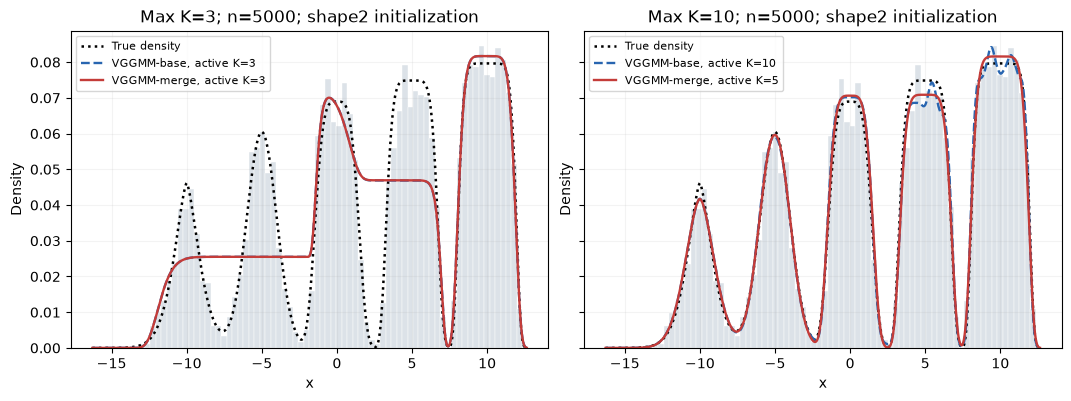

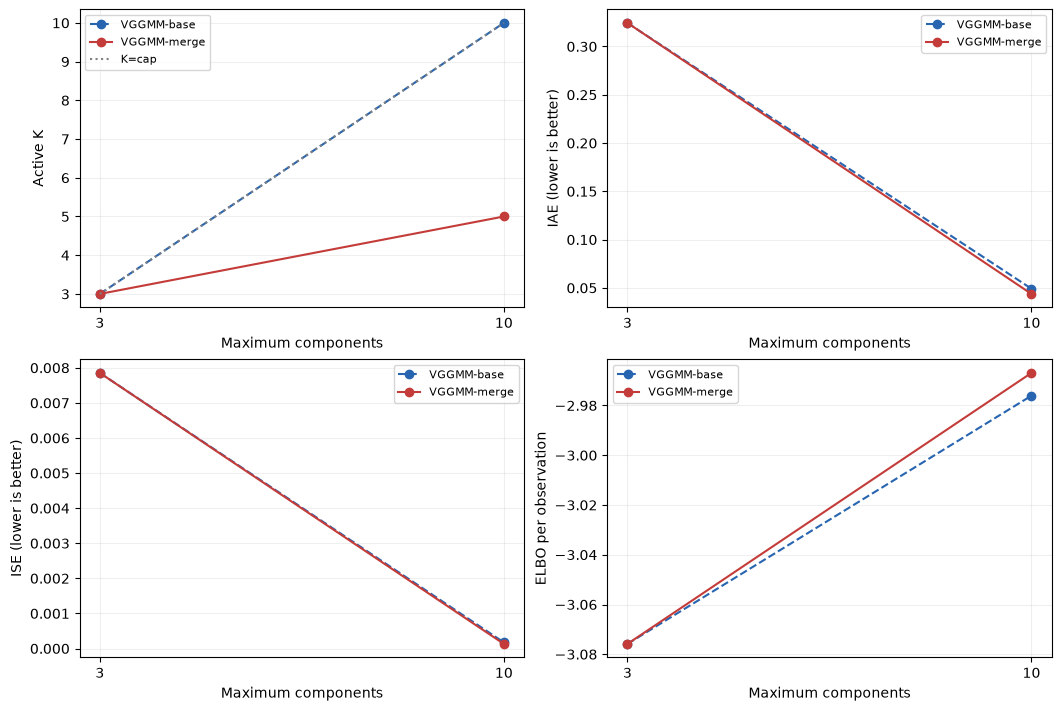

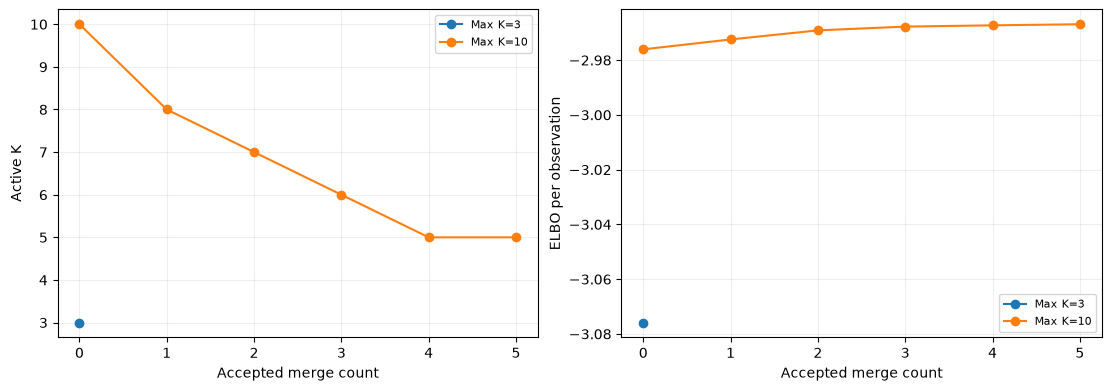

In [5]:
truth5 = ex.ggd_reference_5()
X5 = ex.sample_mixture(truth5, N, SEED)
capacity = ex.run_cap_experiment(
    X5, truth5, caps=(3, 10), config=BASE_CONFIG,
    name="capacity_control", output_root=OUTPUT_ROOT, include_vgm=False)
ex.show_cap_results(capacity)
ex.plot_cap_results(capacity, formats=FIGURE_FORMATS)

## 4. 실제 자료 — Abalone Whole_weight
원자료를 먼저 80/20으로 나누고 학습 표본만 fit에 전달합니다. 참 밀도와 참 K는 알려져 있지 않습니다.
data/abalone.data가 없을 때만 공식 UCI 원자료를 내려받습니다. 이 배포 폴더에는 검증에 쓴 원자료 사본이 포함됩니다.


abalone_whole_weight: seed=20260912, train=3341, test=836, Max_K=10
    merge (4, 5): K 10->9, ELBO/n +0.0015017
    merge (2, 3): K 9->8, ELBO/n +0.00138954
    merge (1, 2): K 8->7, ELBO/n +0.000441398
    merge (4, 6): K 7->6, ELBO/n +0.000991975
    merge (8, 9): K 6->5, ELBO/n +0.0031942
    merge (1, 4): K 5->4, ELBO/n +0.000461504
    merge (7, 8): K 4->3, ELBO/n +0.0037618
    merge (1, 7): K 3->2, ELBO/n +0.0138033
VGGMM-base: K=10, test LL=-0.639339, 90.00s, converged=True | VGGMM-merge: K=2, test LL=-0.653160, 161.58s, converged=True | VGM: K=5, test LL=-0.644723, 5.57s, converged=True
abalone_whole_weight: seed=20260913, train=3341, test=836, Max_K=10
    merge (2, 3): K 10->9, ELBO/n +0.00149774
    merge (4, 5): K 9->8, ELBO/n +0.00117615
    merge (1, 2): K 8->7, ELBO/n +0.000880838
    merge (1, 4): K 7->6, ELBO/n +0.00219968
    merge (1, 6): K 6->5, ELBO/n +0.00145004
    merge (7, 8): K 5->4, ELBO/n +0.000661183
    merge (7, 9): K 4->3, ELBO/n +0.0054307
    merge (

,Seed,Method,Active_K,Test_LL_per_obs,Negative_mass,Fit_s,Merge_extra_s,Converged,Accepted_merges,Inner_nonconverged,Failed_starts,Status
0,20260912,VGGMM-base,10,-0.639339,0.000617,89.999351,0.000000,True,0,0.0,0,ok
1,20260912,VGGMM-merge,2,-0.653160,0.008663,161.576222,71.576670,True,8,0.0,0,ok
2,20260912,VGM,5,-0.644723,0.006725,5.573690,0.000000,True,0,NaN,0,ok
3,20260913,VGGMM-base,10,-0.631257,0.000517,62.771106,0.000000,True,0,0.0,0,ok
4,20260913,VGGMM-merge,2,-0.638673,0.009127,116.645247,53.873919,True,8,0.0,0,ok
5,20260913,VGM,4,-0.634796,0.007217,7.739476,0.000000,True,0,NaN,0,ok
6,20260914,VGGMM-base,10,-0.634930,0.000630,50.663237,0.000000,True,0,0.0,0,ok
7,20260914,VGGMM-merge,2,-0.637244,0.008918,115.099876,64.436438,True,8,0.0,0,ok
8,20260914,VGM,4,-0.634562,0.007485,5.924544,0.000000,True,0,NaN,0,ok


,Comparison,Metric,Valid_seeds,Total_seeds,Both_converged_seeds,Mean_delta,SD_delta,Left_wins,Right_wins,Ties
0,VGGMM-merge minus VGM,Delta_Test_LL_per_obs,3,3,3,-0.004999,0.003037,0,3,0
1,VGGMM-merge minus VGM,Delta_Fit_s,3,3,3,124.694545,27.113846,0,3,0
2,VGGMM-merge minus VGGMM-base,Delta_Test_LL_per_obs,3,3,3,-0.007850,0.005766,0,3,0
3,VGGMM-merge minus VGGMM-base,Delta_Fit_s,3,3,3,63.295884,8.906326,0,3,0


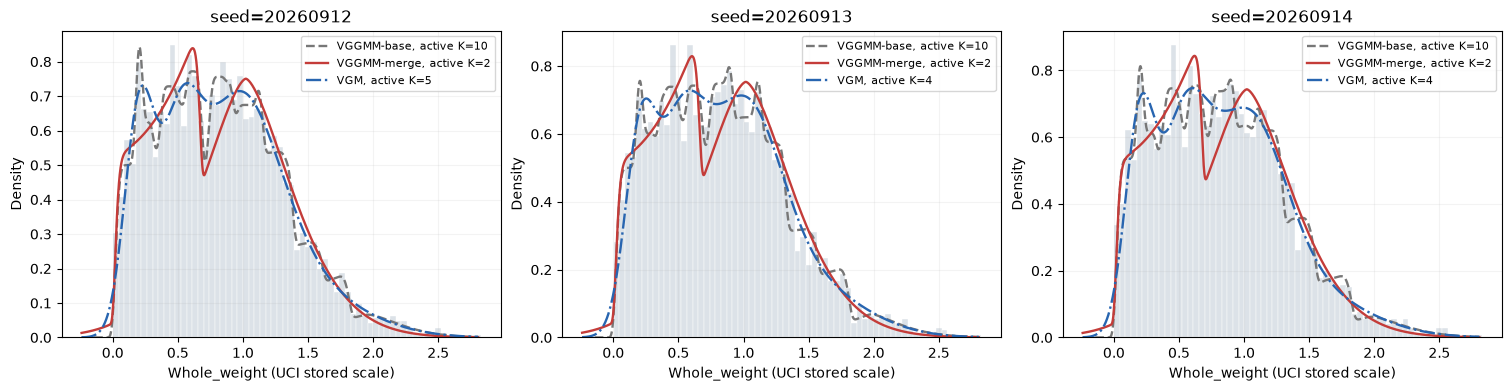

주평가는 full density. Active_*는 문턱으로 자른 출력의 별도 진단입니다.
Fit_s: base는 재사용한 병합 전 적합 시간, merge는 base+병합 전체 시간. 행별 시간을 합치지 마세요.
저장: results\abalone_whole_weight\20261016T092155_451997Z | 실제 적합 시간 합: 412.56 s


In [6]:
abalone_x, abalone_metadata = ex.load_abalone()
real_study = ex.run_study(
    "abalone_whole_weight",
    lambda seed: ex.real_sample(abalone_x, abalone_metadata, seed),
    config=BASE_CONFIG, seeds=SEEDS, output_root=OUTPUT_ROOT,
    vgm_n_init=2, formats=FIGURE_FORMATS)

## 5. 순수 Gaussian 세 성분
scale은 정규분포의 표준편차입니다. GGD 척도 a와 구분합니다.
학습 표본과 별도의 독립 테스트 표본은 각각 N개이며 기존 seed와 seed+1000을 사용합니다.


gaussian_mixture: seed=20260912, train=5000, test=5000, Max_K=10
    merge (1, 2): K 10->9, ELBO/n +0.00095885
    merge (4, 5): K 9->8, ELBO/n +0.000857565
    merge (7, 8): K 8->7, ELBO/n +0.000941901
    merge (6, 7): K 7->6, ELBO/n +0.000237477
    merge (3, 4): K 6->5, ELBO/n +0.000210463
    merge (6, 9): K 5->4, ELBO/n +0.00609218
    merge (1, 3): K 4->3, ELBO/n +0.00101943
VGGMM-base: K=10, test LL=-2.818847, 161.18s, converged=True | VGGMM-merge: K=3, test LL=-2.816663, 306.00s, converged=True | VGM: K=3, test LL=-2.816363, 7.91s, converged=True
gaussian_mixture: seed=20260913, train=5000, test=5000, Max_K=10
    merge (2, 3): K 10->9, ELBO/n +0.000881966
    merge (7, 8): K 9->8, ELBO/n +0.000248946
VGGMM-base: K=10, test LL=-2.838804, 91.91s, converged=True | VGGMM-merge: K=8, test LL=-2.839518, 179.73s, converged=True | VGM: K=3, test LL=-2.833776, 7.54s, converged=True
gaussian_mixture: seed=20260914, train=5000, test=5000, Max_K=10
    merge (6, 7): K 10->9, ELBO/n +0.00

,Seed,Method,Active_K,IAE,ISE,Test_LL_per_obs,Negative_mass,Fit_s,Merge_extra_s,Converged,Accepted_merges,Inner_nonconverged,Failed_starts,Quadrature_OK,Status
0,20260912,VGGMM-base,10,0.066830,0.000417,-2.818847,NaN,161.177858,0.000000,True,0,0.0,0,True,ok
1,20260912,VGGMM-merge,3,0.034390,0.000087,-2.816663,NaN,306.004473,144.826395,True,7,0.0,0,True,ok
2,20260912,VGM,3,0.022694,0.000036,-2.816363,NaN,7.914384,0.000000,True,0,NaN,0,True,ok
3,20260913,VGGMM-base,10,0.071338,0.000543,-2.838804,NaN,91.908110,0.000000,True,0,0.0,0,True,ok
4,20260913,VGGMM-merge,8,0.077204,0.000610,-2.839518,NaN,179.725417,87.817037,True,2,0.0,0,True,ok
5,20260913,VGM,3,0.045353,0.000152,-2.833776,NaN,7.544785,0.000000,True,0,NaN,0,True,ok
6,20260914,VGGMM-base,10,0.072569,0.000529,-2.824152,NaN,74.248346,0.000000,True,0,0.0,0,True,ok
7,20260914,VGGMM-merge,4,0.046540,0.000160,-2.822552,NaN,219.312823,145.064230,True,6,0.0,0,True,ok
8,20260914,VGM,3,0.035041,0.000094,-2.822178,NaN,8.830334,0.000000,True,0,NaN,0,True,ok


,Comparison,Metric,Valid_seeds,Total_seeds,Both_converged_seeds,Mean_delta,SD_delta,Left_wins,Right_wins,Ties
0,VGGMM-merge minus VGM,Delta_IAE,3,3,3,0.018348,0.011694,0,3,0
1,VGGMM-merge minus VGM,Delta_ISE,3,3,3,0.000192,0.000230,0,3,0
2,VGGMM-merge minus VGM,Delta_Test_LL_per_obs,3,3,3,-0.002139,0.003121,0,3,0
3,VGGMM-merge minus VGM,Delta_Fit_s,3,3,3,226.917737,64.543675,0,3,0
4,VGGMM-merge minus VGGMM-base,Delta_IAE,3,3,3,-0.017534,0.020517,2,1,0
5,VGGMM-merge minus VGGMM-base,Delta_ISE,3,3,3,-0.000211,0.000241,2,1,0
6,VGGMM-merge minus VGGMM-base,Delta_Test_LL_per_obs,3,3,3,0.001023,0.001533,2,1,0
7,VGGMM-merge minus VGGMM-base,Delta_Fit_s,3,3,3,125.902799,32.983219,0,3,0


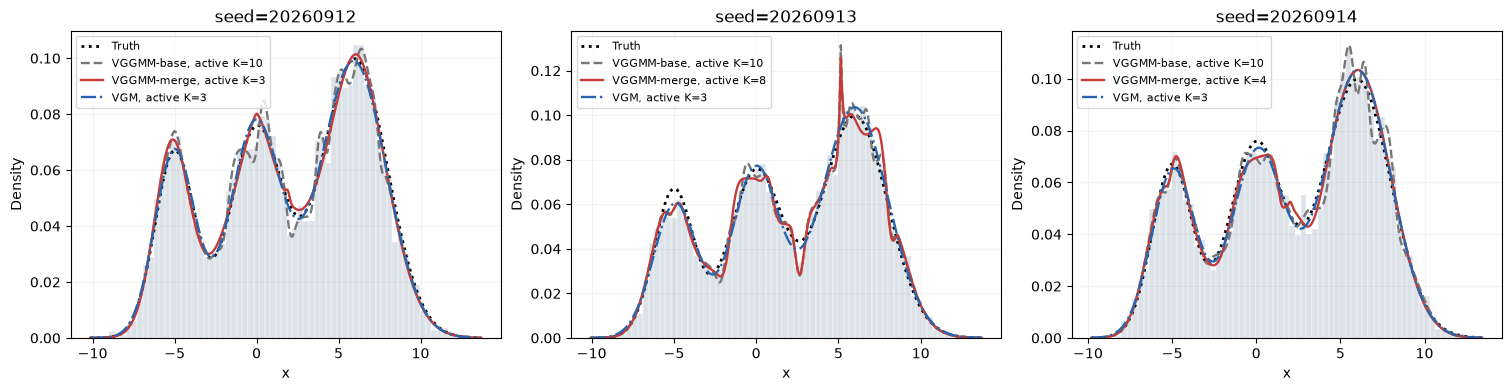

주평가는 full density. Active_*는 문턱으로 자른 출력의 별도 진단입니다.
Fit_s: base는 재사용한 병합 전 적합 시간, merge는 base+병합 전체 시간. 행별 시간을 합치지 마세요.
저장: results\gaussian_mixture\20261016T092850_528261Z | 실제 적합 시간 합: 729.33 s


In [7]:
gaussian_truth = ex.gaussian_reference()
gaussian_study = ex.run_study(
    "gaussian_mixture",
    lambda seed: ex.synthetic_sample(gaussian_truth, seed, n_train=N, n_test=N),
    config=BASE_CONFIG, seeds=SEEDS, output_root=OUTPUT_ROOT,
    vgm_n_init=2, formats=FIGURE_FORMATS)

## 6. 서로 다른 분포족의 혼합
Gaussian + Laplace + Student-t + skew-normal의 기존 생성식입니다.
K=4를 강제하지 않고 full density, 테스트 평균 로그밀도와 IAE·ISE를 평가합니다.


heterogeneous_mixture: seed=20260912, train=5000, test=5000, Max_K=10
    merge (0, 1): K 10->9, ELBO/n +0.000495852
    merge (7, 8): K 9->8, ELBO/n +0.000121482
    merge (2, 3): K 8->7, ELBO/n +0.00109997
    merge (2, 4): K 7->6, ELBO/n +0.000794134
VGGMM-base: K=10, test LL=-2.698524, 154.42s, converged=True | VGGMM-merge: K=6, test LL=-2.697903, 215.92s, converged=True | VGM: K=5, test LL=-2.730753, 2.39s, converged=True
heterogeneous_mixture: seed=20260913, train=5000, test=5000, Max_K=10
    merge (0, 1): K 10->9, ELBO/n +0.00144439
    merge (5, 6): K 9->8, ELBO/n +0.000960864
    merge (2, 3): K 8->7, ELBO/n +0.00125751
    merge (8, 9): K 7->6, ELBO/n +0.0016648
    merge (2, 4): K 6->5, ELBO/n +0.00032679
VGGMM-base: K=10, test LL=-2.713433, 99.82s, converged=True | VGGMM-merge: K=5, test LL=-2.713397, 163.17s, converged=True | VGM: K=6, test LL=-2.734865, 1.11s, converged=True
heterogeneous_mixture: seed=20260914, train=5000, test=5000, Max_K=10
    merge (0, 1): K 10->9, 

,Seed,Method,Active_K,IAE,ISE,Test_LL_per_obs,Negative_mass,Fit_s,Merge_extra_s,Converged,Accepted_merges,Inner_nonconverged,Failed_starts,Quadrature_OK,Status
0,20260912,VGGMM-base,10,0.065737,0.000401,-2.698524,NaN,154.423059,0.000000,True,0,0.0,0,True,ok
1,20260912,VGGMM-merge,6,0.065260,0.000499,-2.697903,NaN,215.915890,61.492597,True,4,0.0,0,True,ok
2,20260912,VGM,5,0.169029,0.003554,-2.730753,NaN,2.394285,0.000000,True,0,NaN,0,True,ok
3,20260913,VGGMM-base,10,0.069117,0.000478,-2.713433,NaN,99.819748,0.000000,True,0,0.0,0,True,ok
4,20260913,VGGMM-merge,5,0.059227,0.000386,-2.713397,NaN,163.166147,63.346024,True,5,0.0,0,True,ok
5,20260913,VGM,6,0.162219,0.002738,-2.734865,NaN,1.106044,0.000000,True,0,NaN,0,True,ok
6,20260914,VGGMM-base,10,0.066693,0.000456,-2.720244,NaN,77.424280,0.000000,True,0,0.0,0,True,ok
7,20260914,VGGMM-merge,6,0.071442,0.000512,-2.719439,NaN,162.013363,84.588837,True,4,0.0,0,True,ok
8,20260914,VGM,5,0.166986,0.003687,-2.743867,NaN,1.916551,0.000000,True,0,NaN,0,True,ok


,Comparison,Metric,Valid_seeds,Total_seeds,Both_converged_seeds,Mean_delta,SD_delta,Left_wins,Right_wins,Ties
0,VGGMM-merge minus VGM,Delta_IAE,3,3,3,-0.100768,0.004541,3,0,0
1,VGGMM-merge minus VGM,Delta_ISE,3,3,3,-0.002861,0.000445,3,0,0
2,VGGMM-merge minus VGM,Delta_Test_LL_per_obs,3,3,3,0.026248,0.005905,3,0,0
3,VGGMM-merge minus VGM,Delta_Fit_s,3,3,3,178.559506,30.293974,0,3,0
4,VGGMM-merge minus VGGMM-base,Delta_IAE,3,3,3,-0.001873,0.007418,2,1,0
5,VGGMM-merge minus VGGMM-base,Delta_ISE,3,3,3,0.000021,0.000100,1,2,0
6,VGGMM-merge minus VGGMM-base,Delta_Test_LL_per_obs,3,3,3,0.000487,0.000402,3,0,0
7,VGGMM-merge minus VGGMM-base,Delta_Fit_s,3,3,3,69.809437,12.833058,0,3,0


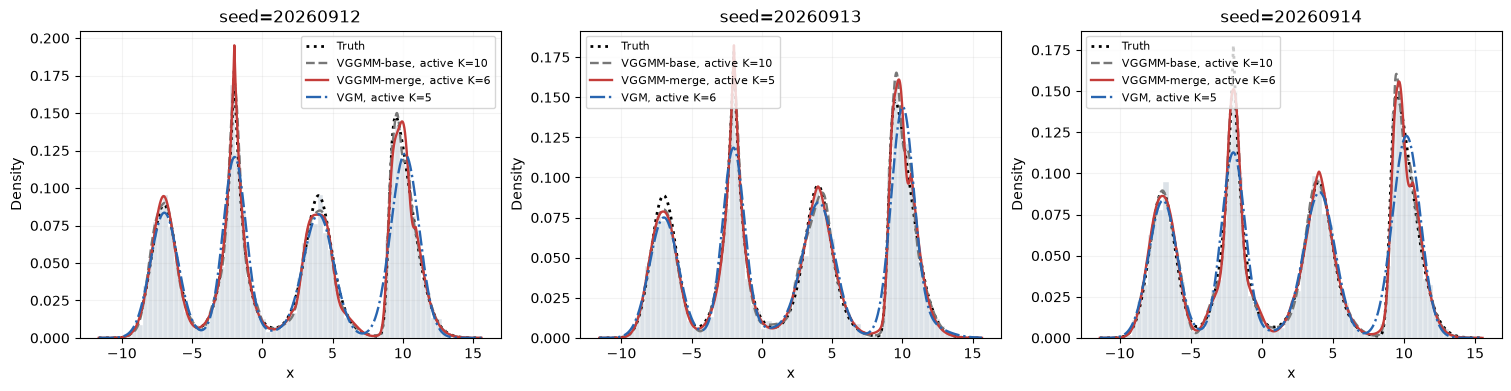

주평가는 full density. Active_*는 문턱으로 자른 출력의 별도 진단입니다.
Fit_s: base는 재사용한 병합 전 적합 시간, merge는 base+병합 전체 시간. 행별 시간을 합치지 마세요.
저장: results\heterogeneous_mixture\20261016T094103_451773Z | 실제 적합 시간 합: 546.51 s


In [8]:
heterogeneous_truth = ex.heterogeneous_reference()
heterogeneous_study = ex.run_study(
    "heterogeneous_mixture",
    lambda seed: ex.synthetic_sample(heterogeneous_truth, seed, n_train=N, n_test=N),
    config=BASE_CONFIG, seeds=SEEDS, output_root=OUTPUT_ROOT,
    vgm_n_init=2, formats=FIGURE_FORMATS)

## 7. 세 연구의 비교 요약
4~6번 실험을 실행한 뒤 사용합니다. Δ는 VGGMM-merge − 비교방법입니다.
ΔIAE·ΔISE·ΔFit_s는 작을수록, ΔTest_LL_per_obs는 클수록 좋습니다.


In [9]:
studies = (real_study, gaussian_study, heterogeneous_study)
battery_metrics = pd.concat([s["table"] for s in studies], ignore_index=True)
battery_summary = pd.concat([
    s["paired_summary"].assign(Study=s["metadata"]["study_id"]) for s in studies
], ignore_index=True)
ex.show_table(battery_summary)

,Comparison,Metric,Valid_seeds,Total_seeds,Both_converged_seeds,Mean_delta,SD_delta,Left_wins,Right_wins,Ties,Study
0,VGGMM-merge minus VGM,Delta_Test_LL_per_obs,3,3,3,-0.004999,0.003037,0,3,0,abalone_whole_weight
1,VGGMM-merge minus VGM,Delta_Fit_s,3,3,3,124.694545,27.113846,0,3,0,abalone_whole_weight
2,VGGMM-merge minus VGGMM-base,Delta_Test_LL_per_obs,3,3,3,-0.007850,0.005766,0,3,0,abalone_whole_weight
3,VGGMM-merge minus VGGMM-base,Delta_Fit_s,3,3,3,63.295884,8.906326,0,3,0,abalone_whole_weight
4,VGGMM-merge minus VGM,Delta_IAE,3,3,3,0.018348,0.011694,0,3,0,gaussian_mixture
5,VGGMM-merge minus VGM,Delta_ISE,3,3,3,0.000192,0.000230,0,3,0,gaussian_mixture
6,VGGMM-merge minus VGM,Delta_Test_LL_per_obs,3,3,3,-0.002139,0.003121,0,3,0,gaussian_mixture
7,VGGMM-merge minus VGM,Delta_Fit_s,3,3,3,226.917737,64.543675,0,3,0,gaussian_mixture
8,VGGMM-merge minus VGGMM-base,Delta_IAE,3,3,3,-0.017534,0.020517,2,1,0,gaussian_mixture
9,VGGMM-merge minus VGGMM-base,Delta_ISE,3,3,3,-0.000211,0.000241,2,1,0,gaussian_mixture


## 8. 기존 VGM 전용 상한 대조
참 K=5, 상한 3/10을 GGD 원분포와 평균·분산을 맞춘 Gaussian 대조에서 비교합니다.
공통 IAE·ISE 적분기를 사용하므로 수치 오차 진단과 꼬리 상계도 같은 정의입니다.


GGD_truth | Max_K=3: active K=3, 0.16s
GGD_truth | Max_K=10: active K=5, 2.48s
Gaussian_control | Max_K=3: active K=3, 0.22s
Gaussian_control | Max_K=10: active K=5, 1.62s


,Scenario,True_K,Max_K,Active_K,At_cap,IAE,ISE,Test_LL_per_obs,Fit_s,Converged,Quadrature_OK
0,GGD_truth,5,3,3,True,0.495753,0.012775,-3.141045,0.161662,True,True
1,GGD_truth,5,10,5,False,0.203888,0.002779,-2.963401,2.477509,True,True
2,Gaussian_control,5,3,3,True,0.448566,0.012506,-3.123545,0.221770,True,True
3,Gaussian_control,5,10,5,False,0.073299,0.000259,-2.945266,1.615310,True,True


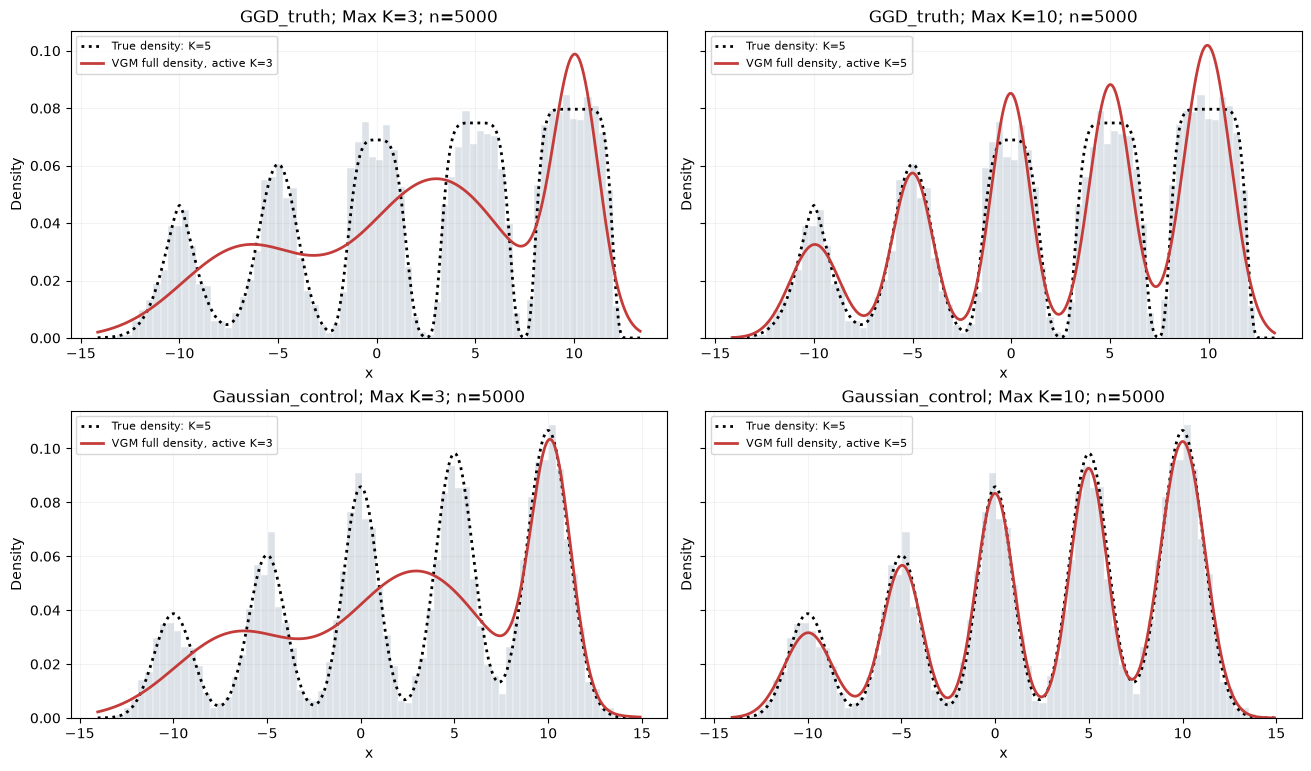

In [10]:
vgm_capacity = ex.run_vgm_cap_experiment(
    n=N, seed=SEED, caps=(3, 10), gaussian_control=True,
    config=BASE_CONFIG, output_root=OUTPUT_ROOT, formats=FIGURE_FORMATS)

## 다른 셀에서 결과 재사용
IAE·ISE를 다시 계산하려면 ex.density_errors(truth3, model10.density_)를 호출하면 됩니다.
이 호출은 재적합하지 않습니다. 전체 슬롯 밀도는 model10.full_density_입니다.

모든 결과는 실험 이름별 results 폴더에 저장됩니다.
적합 수렴, 병합 탐색 종료, 참 K 복원, 밀도 정확도는 별개의 진단입니다.
shape2는 초기 형상만 2로 정하며 b=2 고정 Gaussian 모형으로 바꾸지 않습니다.
